# 307 — Pharmacological Phenotype Framework

Characterize GDSC response measurements in the harmonized pharmacology cohort and export a **drug-specific model–compound phenotype table**. The analytical unit is the unique `ModelID`–`DRUG_ID` pair; responses from different drugs are not pooled to construct a global model sensitivity score.

The analysis is descriptive. It does not establish clinical drug resistance, infer lineage causality, or select a universally optimal response metric.

## 1. Inputs and cohort integrity

In [1]:
# =============================================================================
# Imports and paths
# =============================================================================
from pancancer_epigenetics.utils.paths import Paths, project_relative_path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

INTERMEDIATE_DIR = Paths.pharmacology
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 120

pharmacology = pd.read_csv(
    INTERMEDIATE_DIR / "306_integrated_pharmacology_cohort.csv"
)
drug_metadata = pd.read_csv(INTERMEDIATE_DIR / "306_drug_metadata.csv")
drug_response = pd.read_csv(INTERMEDIATE_DIR / "306_gdsc_drug_response.csv")

print("Cohort:", pharmacology.shape)
print("Drug metadata:", drug_metadata.shape)
print("Drug responses:", drug_response.shape)

Cohort: (712, 8)
Drug metadata: (295, 4)
Drug responses: (180335, 9)


In [2]:
# =============================================================================
# Validate and integrate cohort annotations
# =============================================================================
assert pharmacology["SangerModelID"].notna().all()
assert pharmacology["SangerModelID"].is_unique
assert pharmacology["ModelID"].notna().all()
assert pharmacology["ModelID"].is_unique
assert drug_response["SANGER_MODEL_ID"].notna().all()

n_input = len(drug_response)
drug_response = drug_response.merge(
    pharmacology,
    left_on="SANGER_MODEL_ID",
    right_on="SangerModelID",
    how="left",
    validate="many_to_one",
    indicator=True,
)
merge_counts = drug_response["_merge"].value_counts()
display(merge_counts.rename("records").to_frame())
assert len(drug_response) == n_input
assert (drug_response["_merge"] == "both").all(), (
    "Responses outside the harmonized cohort require investigation."
)
drug_response = drug_response.drop(columns="_merge")

pair_columns = ["ModelID", "DRUG_ID"]
assert drug_response[pair_columns].notna().all().all()
assert not drug_response.duplicated(pair_columns).any(), (
    "Multiple records for a model–drug pair require adjudication."
)
assert drug_response["OncotreeLineage"].notna().all()
assert drug_response.groupby("DRUG_ID")["DRUG_NAME"].nunique().eq(1).all()

response_metrics = ["LN_IC50", "AUC", "Z_SCORE"]
assert drug_response[response_metrics].apply(
    lambda col: np.isfinite(col.to_numpy()).all()
).all(), "Non-finite response values require investigation."

print("Unique models:", drug_response["ModelID"].nunique())
print("Unique DRUG_IDs:", drug_response["DRUG_ID"].nunique())
print("Unique drug names:", drug_response["DRUG_NAME"].nunique())
print("Unique model–drug pairs:", len(drug_response))

,records
_merge,
both,180335
left_only,0
right_only,0


Unique models: 712
Unique DRUG_IDs: 295
Unique drug names: 286
Unique model–drug pairs: 180335


## 2. Response metrics and compound coverage

,count,mean,std,min,25%,50%,75%,max,missing
LN_IC50,180335.0,2.865672,2.763330,-8.747724,1.545170,3.277617,4.753843,13.820189,0
AUC,180335.0,0.884061,0.145100,0.006282,0.851675,0.944710,0.974803,0.998904,0
Z_SCORE,180335.0,0.030002,1.006711,-8.254501,-0.626183,0.040698,0.685700,6.160835,0
RMSE,180335.0,0.082291,0.042330,0.003274,0.050958,0.075596,0.105215,0.299984,0


,n_models
count,295.000000
mean,611.305085
std,126.529157
min,136.000000
25%,552.000000
50%,655.000000
75%,703.000000
max,712.000000


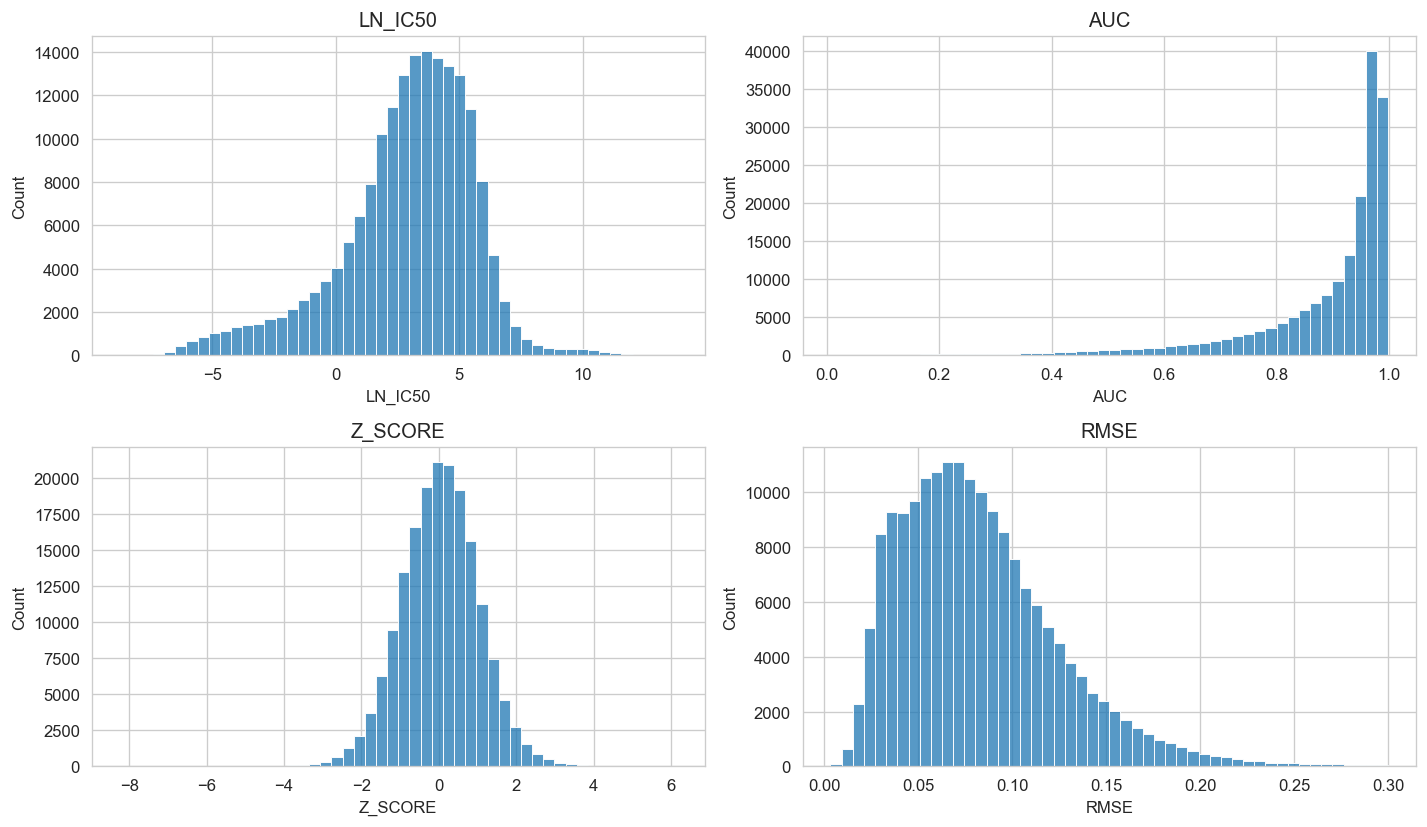

In [3]:
# =============================================================================
# Metric distributions and compound coverage
# =============================================================================
metric_columns = response_metrics + ["RMSE"]
metric_summary = drug_response[metric_columns].describe().T
metric_summary["missing"] = drug_response[metric_columns].isna().sum()
display(metric_summary)

drug_coverage = (
    drug_response.groupby(["DRUG_ID", "DRUG_NAME"])
    .agg(n_models=("ModelID", "nunique"))
    .reset_index()
)
display(drug_coverage["n_models"].describe().to_frame("n_models"))

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, metric in zip(axes.flat, metric_columns):
    sns.histplot(drug_response[metric].dropna(), bins=50, ax=ax)
    ax.set_title(metric)
plt.tight_layout()
plt.show()

## 3. Within-drug metric concordance

In [4]:
# =============================================================================
# Spearman concordance on matched models within each compound
# =============================================================================
metric_pairs = [
    ("LN_IC50", "AUC"),
    ("LN_IC50", "Z_SCORE"),
    ("AUC", "Z_SCORE"),
]
concordance_records = []
for drug_id, group in drug_response.groupby("DRUG_ID"):
    for metric_a, metric_b in metric_pairs:
        valid = group[[metric_a, metric_b]].dropna()
        rho = np.nan
        if (
            len(valid) >= 3
            and valid[metric_a].nunique() >= 2
            and valid[metric_b].nunique() >= 2
        ):
            rho = spearmanr(valid[metric_a], valid[metric_b]).statistic
        concordance_records.append(
            {
                "DRUG_ID": drug_id,
                "metric_a": metric_a,
                "metric_b": metric_b,
                "n_models": len(valid),
                "spearman_rho": rho,
            }
        )
phenotype_concordance = pd.DataFrame(concordance_records)
display(
    phenotype_concordance.groupby(["metric_a", "metric_b"])[
        "spearman_rho"
    ].agg(["count", "median", "min", "max"])
)

count    median      min       max
metric_a metric_b                                    
AUC      Z_SCORE     295  0.799946 -0.38427  0.998526
LN_IC50  AUC         295  0.799946 -0.38427  0.998526
         Z_SCORE     295  1.000000  1.00000  1.000000

## 4. Compound-specific lineage characterization

Lineage summaries are descriptive. Only lineages with at least five tested models enter the exploratory range of lineage medians; this threshold is a reporting rule, not a significance criterion.

,n_lineages
count,295.000000
mean,25.983051
std,1.232931
min,22.000000
25%,25.000000
50%,26.000000
75%,27.000000
max,27.000000


Compounds eligible for median-range assessment: 295


,median_range
count,295.000000
mean,2.801374
std,1.102032
min,1.098680
25%,1.956657
50%,2.515816
75%,3.534591
max,6.988976


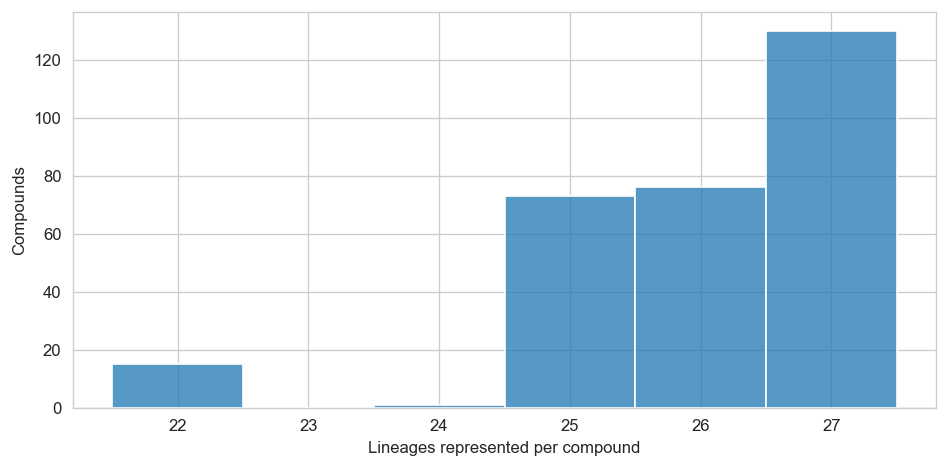

In [5]:
# =============================================================================
# Lineage coverage and within-compound differences
# =============================================================================
MIN_MODELS_PER_LINEAGE = 5
MIN_LINEAGES_PER_DRUG = 2

lineage_drug_summary = (
    drug_response.groupby(["DRUG_ID", "OncotreeLineage"])
    .agg(
        n_models=("ModelID", "nunique"),
        median_ln_ic50=("LN_IC50", "median"),
    )
    .reset_index()
)
lineage_coverage = (
    lineage_drug_summary.groupby("DRUG_ID")
    .agg(n_lineages=("OncotreeLineage", "nunique"))
    .reset_index()
)
display(lineage_coverage["n_lineages"].describe().to_frame("n_lineages"))

eligible_lineages = lineage_drug_summary.loc[
    lineage_drug_summary["n_models"] >= MIN_MODELS_PER_LINEAGE
]
lineage_heterogeneity = (
    eligible_lineages.groupby("DRUG_ID")
    .agg(
        n_lineages=("OncotreeLineage", "nunique"),
        min_median=("median_ln_ic50", "min"),
        max_median=("median_ln_ic50", "max"),
    )
    .reset_index()
)
lineage_heterogeneity = lineage_heterogeneity.loc[
    lineage_heterogeneity["n_lineages"] >= MIN_LINEAGES_PER_DRUG
].copy()
lineage_heterogeneity["median_range"] = (
    lineage_heterogeneity["max_median"]
    - lineage_heterogeneity["min_median"]
)
print("Compounds eligible for median-range assessment:", len(lineage_heterogeneity))
display(lineage_heterogeneity["median_range"].describe().to_frame("median_range"))

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(lineage_coverage["n_lineages"], discrete=True, ax=ax)
ax.set(xlabel="Lineages represented per compound", ylabel="Compounds")
plt.tight_layout()
plt.show()

## 5. Within-drug transformations and representation diagnostics

Z-standardization and percentile ranks are **diagnostic candidates**, not replacements for the original measurements. Dispersion statistics across metrics use different scales and are not comparative performance scores.

,count,mean,std,min,median,max
LN_IC50,180335.0,2.865672e+00,2.763330,-8.747724,3.277617,13.820189
LN_IC50_DRUG_Z,180335.0,9.269148e-18,0.999185,-8.196941,0.010102,6.250477
LN_IC50_DRUG_RANK,180335.0,5.008179e-01,0.288676,0.001404,0.500715,1.000000


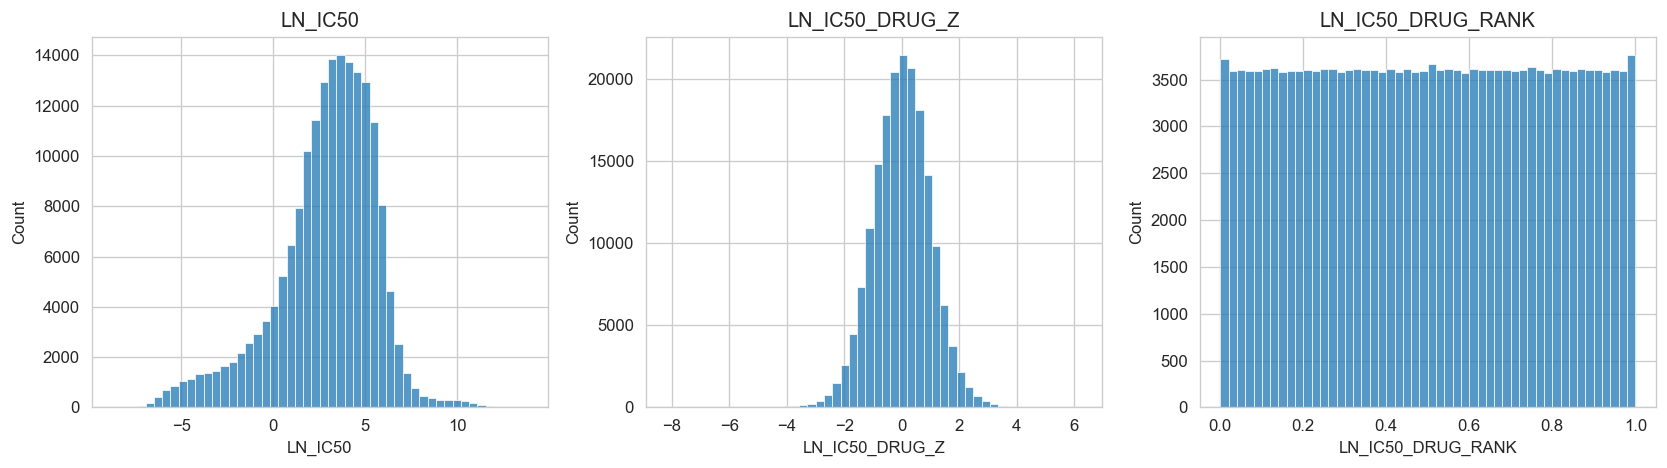

In [6]:
# =============================================================================
# Candidate transformations of LN_IC50
# =============================================================================
by_drug = drug_response.groupby("DRUG_ID")["LN_IC50"]
drug_mean = by_drug.transform("mean")
drug_std = by_drug.transform("std")

drug_response["LN_IC50_DRUG_Z"] = (
    (drug_response["LN_IC50"] - drug_mean)
    / drug_std.where(drug_std > 0)
)
drug_response["LN_IC50_DRUG_RANK"] = by_drug.rank(pct=True)

normalization_metrics = [
    "LN_IC50", "LN_IC50_DRUG_Z", "LN_IC50_DRUG_RANK"
]
display(
    drug_response[normalization_metrics]
    .agg(["count", "mean", "std", "min", "median", "max"])
    .T
)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, metric in zip(axes, normalization_metrics):
    sns.histplot(drug_response[metric].dropna(), bins=50, ax=ax)
    ax.set_title(metric)
plt.tight_layout()
plt.show()

In [7]:
# =============================================================================
# Data-derived representation diagnostics
# =============================================================================
diagnostic_records = []
for metric in response_metrics:
    drug_stats = drug_response.groupby("DRUG_ID")[metric].agg(
        n_observations="count",
        std="std",
        minimum="min",
        maximum="max",
    )
    diagnostic_records.append(
        {
            "metric": metric,
            "n_observations": drug_response[metric].notna().sum(),
            "n_drugs": (drug_stats["n_observations"] > 0).sum(),
            "missing_pct": 100 * drug_response[metric].isna().mean(),
            "median_drug_observations": drug_stats.loc[
                drug_stats["n_observations"] > 0, "n_observations"
            ].median(),
            "median_within_drug_sd": drug_stats["std"].median(),
            "median_within_drug_range": (
                drug_stats["maximum"] - drug_stats["minimum"]
            ).median(),
            "n_zero_variance_drugs": (drug_stats["std"] == 0).sum(),
        }
    )
representation_diagnostics = pd.DataFrame(diagnostic_records).set_index("metric")
display(representation_diagnostics)

,n_observations,n_drugs,missing_pct,median_drug_observations,median_within_drug_sd,median_within_drug_range,n_zero_variance_drugs
metric,,,,,,,
LN_IC50,180335,295,0.0,655.0,1.365615,8.831338,0
AUC,180335,295,0.0,655.0,0.065445,0.461191,0
Z_SCORE,180335,295,0.0,655.0,1.009156,6.463701,0


## 6. Phenotype export

Export the original `LN_IC50`, `AUC`, and `Z_SCORE` measurements per model–drug pair. Candidate transformations remain exploratory diagnostics and are not included in the output. No primary metric is selected in this notebook.

In [8]:
# =============================================================================
# Validate and export model–drug phenotypes
# =============================================================================
output_columns = ["ModelID", "DRUG_ID", "DRUG_NAME"] + response_metrics
phenotype_table = drug_response[output_columns].copy()

assert len(phenotype_table) == len(drug_response)
assert not phenotype_table.duplicated(["ModelID", "DRUG_ID"]).any()
assert phenotype_table[output_columns].notna().all().all()
assert phenotype_table["ModelID"].nunique() == pharmacology["ModelID"].nunique()
assert phenotype_table["DRUG_ID"].nunique() == drug_metadata["DRUG_ID"].nunique()

output_path = INTERMEDIATE_DIR / "307_drug_specific_phenotypes.parquet"
phenotype_table.to_parquet(output_path, index=False)
print("Saved:", project_relative_path(output_path))
print("Rows:", len(phenotype_table))
print("Models:", phenotype_table["ModelID"].nunique())
print("Compounds:", phenotype_table["DRUG_ID"].nunique())
display(phenotype_table.head())

Saved: data/interim/pharmacology/307_drug_specific_phenotypes.parquet
Rows: 180335
Models: 712
Compounds: 295


,ModelID,DRUG_ID,DRUG_NAME,LN_IC50,AUC,Z_SCORE
0,ACH-001711,1003,Camptothecin,-1.463887,0.930220,0.433123
1,ACH-000052,1003,Camptothecin,-4.869455,0.614970,-1.421100
2,ACH-000087,1003,Camptothecin,-5.142961,0.582439,-1.570016
3,ACH-000644,1003,Camptothecin,-1.235034,0.867348,0.557727
4,ACH-000905,1003,Camptothecin,-2.632632,0.834067,-0.203221
